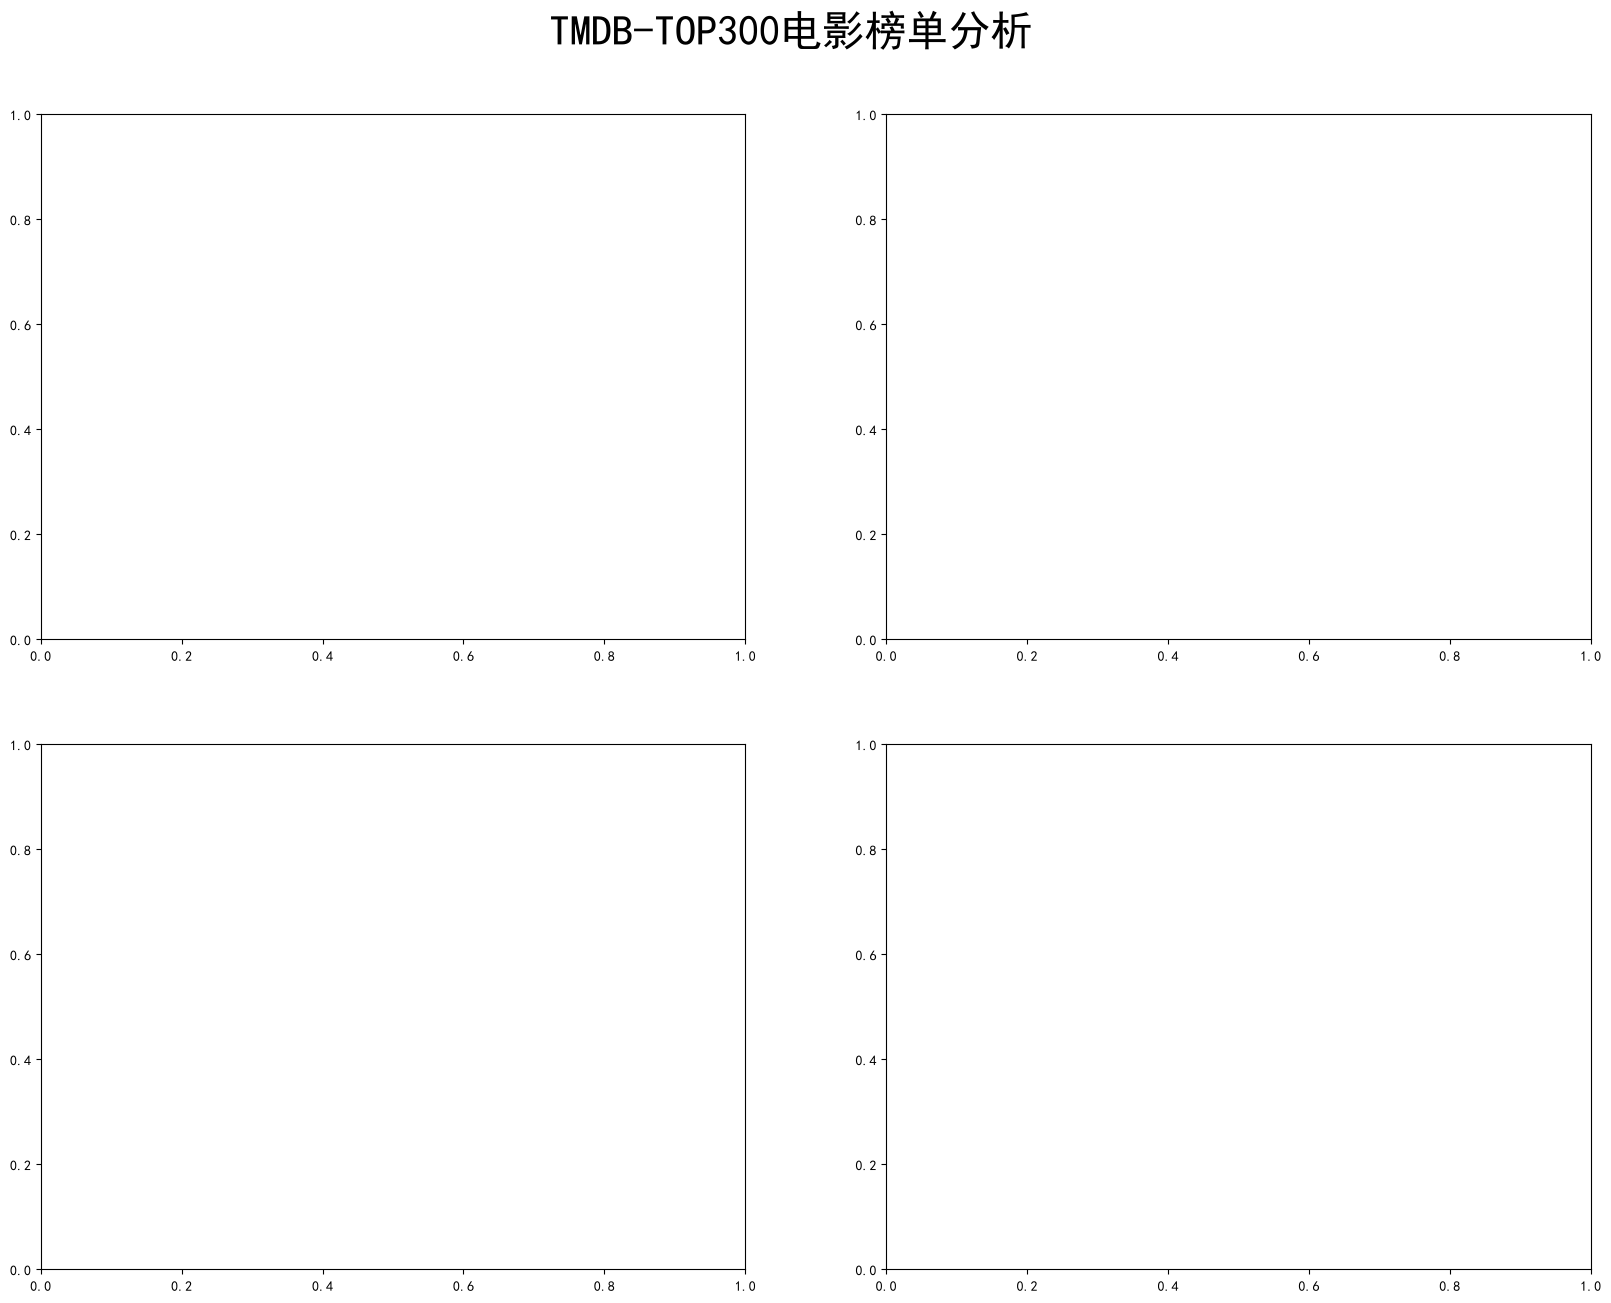

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
plt.rcParams['font.sans-serif'] = ['SimHei']#显示中文并显示黑体
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(20,15),dpi=100)
fig.suptitle('TMDB-TOP300电影榜单分析',fontsize=30,x=0.5,y=0.95)#添加大标题，fontsize是控制标题的字体大小，xy是控制标题的位置x是横向 y 是纵轴的位置
axes1:Axes=ax[0,0]
axes2:Axes=ax[0,1]
axes3:Axes=ax[1,0]
axes4:Axes=ax[1,1]
#读取数据
#int64:整形数据，不支持空值,要让年份不带.0 则要把类型改为Int64的类型
#Int64:整形数据，支持空值
data=pd.read_csv('data/movies.csv',usecols=["电影名","年份","上映时间","类型","时长","评分","语言"],dtype={'年份':'Int64'})#使用usecols来显示需要用的列名，不是所有的列都要用
data
#需求一：统计电影中，每年上映的电影变化，用折线图表示
#1.1 优于抓取的数据可能有年份丢失，所以要进行处理
# print(data.isnull().sum())
data['年份']=data['年份'].fillna(data['上映时间'].str[0:4])#将上映时间的年份剪切给年份，并更新年份
data.head(100)
# data[data['年份']<=0] 检查是否有年份异常值
#进行年份分组
year_count=data.groupby('年份')['时长'].count()
#组装数据 x轴为年份 y轴为数量
#x 轴数据
min_year=year_count.index.min()
max_year=year_count.index.max()
x=[i for i in arange(min_year,max_year+1)]#最小值年份，最大值年份
#y周数据
